# Resultados de segmentación

En este capítulo comparamos los modelos en el conjunto de test (93 imágenes), que evaluamos una sola vez con el post-proceso congelado en validación. La unidad de análisis es la imagen: cada cifra es la media sobre imágenes de la media entre semillas, con su IC 95 % *bootstrap* (10 000 remuestreos de imágenes). Las pruebas siguen el plan del capítulo {doc}`03_declaracion_apriori`. Los resultados los generan `python scripts/eval_seg.py test` y `python scripts/analysis.py seg`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, CELL_NAMES, MUTED, ci, need, style

style()
pd.set_option("display.precision", 3)
R = need("analysis/seg_stats/stats.pkl")
L = R["labels"]; models = R["models"]
COL = {m: CAT[i] for i, m in enumerate(["unetpp_main", "maskrcnn_main", "cellpose_zeroshot", "cellpose_finetune", "sam_box",
                                         "sam_auto", "hover_main", "otsu_watershed"])}

## Tabla principal

In [2]:
S = R["summary"].loc[[m for m in models]]
tab = pd.DataFrame({
    "modelo": [L[m] for m in S.index], "semillas": S.n_seeds.astype(int),
    "AP@[0.5:0.95]": [ci(a, b, c) for a, b, c in zip(S.ap, S.ap_lo, S.ap_hi)],
    "DE entre semillas": S.ap_seed_sd, "AP50": S.ap50, "AP75": S.ap75, "PQ": S.pq, "AJI": S.aji,
    "F1 de instancia": S.inst_f1, "Dice": S.dice, "HD95 (px)": S.hd95, "F1 de borde": S.boundary_f1,
    "error de conteo": S.count_error})
tab.sort_values("AP@[0.5:0.95]", ascending=False).style.hide(axis="index").format(precision=3, na_rep="—")

modelo,semillas,AP@[0.5:0.95],DE entre semillas,AP50,AP75,PQ,AJI,F1 de instancia,Dice,HD95 (px),F1 de borde,error de conteo
Cellpose ajustado,1,"0.253 [0.226, 0.281]",—,0.548,0.197,0.491,0.434,0.675,0.675,46.176,0.669,-27.226
Mask R-CNN,3,"0.228 [0.202, 0.254]",0.004,0.488,0.182,0.453,0.402,0.622,0.639,45.920,0.633,-36.563
U-Net++,3,"0.214 [0.188, 0.240]",0.002,0.483,0.157,0.439,0.444,0.613,0.746,29.768,0.705,-0.437
SAM (cajas),1,"0.191 [0.168, 0.216]",—,0.454,0.131,0.413,0.378,0.587,0.626,45.467,0.605,-36.312
Hover (NP+HV),1,"0.096 [0.079, 0.114]",—,0.222,0.073,0.235,0.277,0.335,0.737,33.379,0.650,-46.452
Cellpose cero-shot,1,"0.094 [0.078, 0.111]",—,0.224,0.070,0.233,0.211,0.334,0.423,93.789,0.387,-14.215
SAM automático,1,"0.025 [0.022, 0.028]",—,0.056,0.019,0.073,0.125,0.105,0.276,95.596,0.279,74.935
Otsu + watershed,1,"0.010 [0.008, 0.013]",—,0.034,0.004,0.040,0.111,0.064,0.360,84.172,0.273,194.484


In [3]:
best = S.ap.idxmax(); second = S.ap.drop(best).idxmax()
display(Markdown(
    f"El mejor modelo en test es **{L[best]}**, con AP@[0.5:0.95] = {ci(S.ap[best], S.ap_lo[best], S.ap_hi[best])}, seguido de "
    f"**{L[second]}** con {ci(S.ap[second], S.ap_lo[second], S.ap_hi[second])}. "
    + (f"La DE entre semillas de {L[best]} es {S.ap_seed_sd[best]:.3f}, frente a una DE entre imágenes de {S.ap_image_sd[best]:.3f}"
       + (": la variación entre imágenes domina la incertidumbre del promedio." if S.ap_image_sd[best] > S.ap_seed_sd[best] else ".")
       if S.n_seeds[best] > 1 else f"{L[best]} tiene una sola corrida (no depende de una semilla de entrenamiento); su DE entre imágenes es {S.ap_image_sd[best]:.3f}.")))

El mejor modelo en test es **Cellpose ajustado**, con AP@[0.5:0.95] = 0.253 [0.226, 0.281], seguido de **Mask R-CNN** con 0.228 [0.202, 0.254]. Cellpose ajustado tiene una sola corrida (no depende de una semilla de entrenamiento); su DE entre imágenes es 0.136.

El AP de Sartorius es exigente: promedia sobre umbrales de IoU hasta 0.95, donde casi ninguna célula de forma irregular alcanza el emparejamiento. Por eso AP50 y AP75 ayudan a leer la tabla: la caída de AP50 a AP75 mide cuánto del error es de contorno y no de detección.

## Comparación estadística entre modelos

In [4]:
C = R["comparisons"]
display(Markdown(f"Friedman sobre {C['n_units']} imágenes y {len(models)} modelos: χ² = {C['friedman_stat']:.1f}, "
                 f"p = {C['friedman_p']:.2g}. Diferencia crítica de Nemenyi (α = 0.05): {C['cd']:.2f} rangos."))
pw = C["pairwise"].copy()
pw["A"] = pw.A.map(L); pw["B"] = pw.B.map(L)
pw["diferencia [IC 95 %]"] = [ci(a, b, c) for a, b, c in zip(pw.mean_diff, pw.diff_lo, pw.diff_hi)]
pw[["A", "B", "diferencia [IC 95 %]", "cohen_dz", "cliffs_delta", "p_holm", "relevante"]].rename(
    columns={"cohen_dz": "d de Cohen", "cliffs_delta": "δ de Cliff", "p_holm": "p (Holm)", "relevante": "significativa y ≥ 0.02"}
).style.hide(axis="index").format(precision=3)

Friedman sobre 93 imágenes y 8 modelos: χ² = 476.9, p = 7.5e-99. Diferencia crítica de Nemenyi (α = 0.05): 1.09 rangos.

A,B,diferencia [IC 95 %],d de Cohen,δ de Cliff,p (Holm),significativa y ≥ 0.02
U-Net++,Hover (NP+HV),"0.118 [0.100, 0.138]",1.249,0.569,0.000,True
U-Net++,Mask R-CNN,"-0.014 [-0.021, -0.007]",-0.385,-0.065,0.006,False
U-Net++,Cellpose cero-shot,"0.120 [0.088, 0.152]",0.760,0.559,0.000,True
U-Net++,Cellpose ajustado,"-0.039 [-0.046, -0.032]",-1.156,-0.169,0.000,True
U-Net++,SAM (cajas),"0.022 [0.013, 0.032]",0.466,0.105,0.000,True
U-Net++,SAM automático,"0.189 [0.164, 0.215]",1.491,0.936,0.000,True
U-Net++,Otsu + watershed,"0.204 [0.177, 0.230]",1.526,0.980,0.000,True
Hover (NP+HV),Mask R-CNN,"-0.132 [-0.152, -0.113]",-1.372,-0.635,0.000,True
Hover (NP+HV),Cellpose cero-shot,"0.001 [-0.019, 0.022]",0.014,0.017,0.509,False
Hover (NP+HV),Cellpose ajustado,"-0.158 [-0.179, -0.138]",-1.570,-0.695,0.000,True


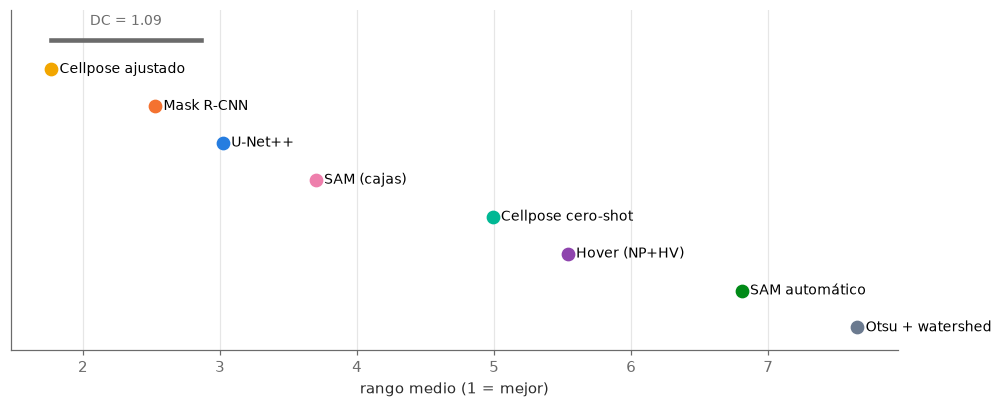

In [5]:
ranks = C["mean_ranks"]
fig, ax = plt.subplots(figsize=(9, 1.6 + 0.25 * len(ranks)))
for k, (m, r) in enumerate(ranks.items()):
    ax.plot(r, k, "o", color=COL.get(m, MUTED), ms=8)
    ax.text(r + 0.06, k, L[m], va="center", fontsize=9)
lo = ranks.iloc[0]
ax.plot([lo, lo + C["cd"]], [-0.8, -0.8], color=MUTED, lw=3)
ax.text(lo + C["cd"] / 2, -1.2, f"DC = {C['cd']:.2f}", ha="center", color=MUTED, fontsize=9)
ax.set(xlabel="rango medio (1 = mejor)", yticks=[], ylim=(len(ranks) - 0.4, -1.6))
ax.grid(axis="y", visible=False)
plt.show()

En el diagrama de diferencia crítica, dos modelos cuyos rangos medios distan menos que la barra DC no se distinguen con la prueba de Nemenyi {cite:p}`demsar2006comparisons`. La conclusión principal la tomamos de las pruebas de Wilcoxon–Holm de la tabla anterior, que son más potentes; el diagrama resume el orden.

In [6]:
mx = C.get("mixed", {})
if "params" in mx:
    pv = pd.DataFrame({"coeficiente": mx["params"], "p": mx["pvalues"]}).drop(index=["Group Var"], errors="ignore")
    display(pv)
    icc = mx["group_var"] / (mx["group_var"] + mx["resid_var"])
    # concordancia con las comparaciones pareadas: cada coeficiente es «modelo − referencia» (primer nivel alfabético)
    pw = C["pairwise"]; coefs = {k[len("C(m)[T."):-1]: k for k in mx["params"].index if k.startswith("C(m)[T.")}
    ref_m = sorted(set(pw.A) | set(pw.B))[0]; agree, n_cmp = 0, 0
    for m_, k_ in coefs.items():
        r_ = pw[((pw.A == m_) & (pw.B == ref_m)) | ((pw.A == ref_m) & (pw.B == m_))]
        if len(r_):
            d_ = r_.mean_diff.iloc[0] * (1 if r_.A.iloc[0] == m_ else -1)
            n_cmp += 1
            agree += int(np.sign(d_) == np.sign(mx["params"][k_]) and (r_.p_holm.iloc[0] < 0.05) == (mx["pvalues"][k_] < 0.05))
    txt = (f"Modelo mixto `AP ~ modelo + (1 | sample_id)`: la varianza entre muestras es {mx['group_var']:.4f} y la residual "
           f"{mx['resid_var']:.4f} (ICC = {icc:.2f}). Frente a {L.get(ref_m, ref_m)} como referencia, {agree} de {n_cmp} coeficientes "
           "coinciden en signo y en significancia (α = 0.05) con la comparación pareada de Wilcoxon–Holm"
           + (": la correlación entre imágenes de una misma muestra no cambia las conclusiones." if agree == n_cmp else
              "; las comparaciones discordantes deben leerse con cautela, porque la dependencia entre imágenes de una misma muestra "
              "altera su significancia."))
    display(Markdown(txt if mx.get("converged", True) else "El modelo mixto no convergió; lo reportamos sin interpretar sus coeficientes."))
else:
    display(Markdown(f"El modelo mixto no se pudo ajustar: {mx.get('error')}."))

,coeficiente,p
Intercept,-1.049e-16,1.000e+00
C(m)[T.cellpose_zeroshot],-1.591e-01,1.177e-47
C(m)[T.hover_main],-1.577e-01,8.194e-47
C(m)[T.maskrcnn_main],-2.572e-02,1.907e-02
C(m)[T.otsu_watershed],-2.430e-01,1.194e-108
C(m)[T.sam_auto],-2.288e-01,1.503e-96
C(m)[T.sam_box],-6.193e-02,1.666e-08
C(m)[T.unetpp_main],-3.949e-02,3.201e-04


Modelo mixto `AP ~ modelo + (1 | sample_id)`: la varianza entre muestras es 0.0000 y la residual 0.0056 (ICC = 0.00). Frente a Cellpose ajustado como referencia, 7 de 7 coeficientes coinciden en signo y en significancia (α = 0.05) con la comparación pareada de Wilcoxon–Holm: la correlación entre imágenes de una misma muestra no cambia las conclusiones.

## RQ1 y H3: estratificación por tipo celular, densidad y tamaño

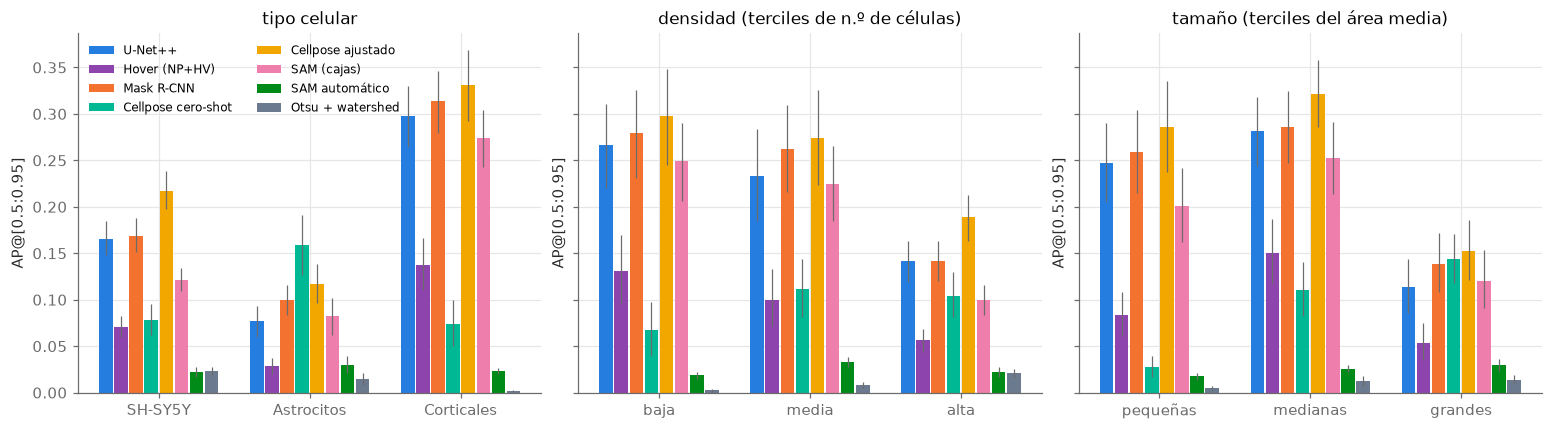

In [7]:
st_ = R["stratified"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, col, order in zip(axes, ("cell_type", "densidad", "tamaño"),
                          (["shsy5y", "astro", "cort"], ["baja", "media", "alta"], ["pequeñas", "medianas", "grandes"])):
    t = st_[col]
    w = 0.8 / len(models)
    for k, m in enumerate(models):
        g = t[t.model == m].set_index("nivel").reindex(order)
        x = np.arange(len(order)) + (k - len(models) / 2 + 0.5) * w
        ax.bar(x, g.ap, w * 0.9, color=COL.get(m, MUTED), label=L[m])
        ax.errorbar(x, g.ap, yerr=[g.ap - g.lo, g.hi - g.ap], fmt="none", ecolor=MUTED, lw=0.8)
    ax.set_xticks(range(len(order)), [CELL_NAMES.get(o, o) for o in order])
    ax.set(title={"cell_type": "tipo celular", "densidad": "densidad (terciles de n.º de células)",
                  "tamaño": "tamaño (terciles del área media)"}[col], ylabel="AP@[0.5:0.95]")
axes[0].legend(fontsize=8, ncol=2)
plt.show()

In [8]:
h3 = st_["h3"]
orders = pd.DataFrame({CELL_NAMES[k]: [L[m] for m in v] for k, v in h3["orders"].items()}, index=range(1, len(models) + 1))
orders.index.name = "puesto"
display(orders)
ip = {k: v for k, v in h3["interaction_pvalues"].items()} if "error" not in h3["interaction_pvalues"] else {}
display(Markdown(
    f"**H3** {'se refuta' if h3['identical'] else 'no se refuta'}: el orden de los modelos "
    f"{'es idéntico' if h3['identical'] else 'cambia'} entre los tres tipos celulares (W de Kendall = {h3['kendall_w']:.2f}, "
    f"donde 1 indica órdenes idénticos). "
    + (f"En el modelo mixto con interacción modelo × tipo, {sum(p < 0.05 for p in ip.values())} de {len(ip)} términos de interacción "
       f"tienen p < 0.05." if ip else "")))

,Astrocitos,Corticales,SH-SY5Y
puesto,,,
1,Cellpose cero-shot,Cellpose ajustado,Cellpose ajustado
2,Cellpose ajustado,Mask R-CNN,Mask R-CNN
3,Mask R-CNN,U-Net++,U-Net++
4,SAM (cajas),SAM (cajas),SAM (cajas)
5,U-Net++,Hover (NP+HV),Cellpose cero-shot
6,SAM automático,Cellpose cero-shot,Hover (NP+HV)
7,Hover (NP+HV),SAM automático,Otsu + watershed
8,Otsu + watershed,Otsu + watershed,SAM automático


**H3** no se refuta: el orden de los modelos cambia entre los tres tipos celulares (W de Kendall = 0.82, donde 1 indica órdenes idénticos). En el modelo mixto con interacción modelo × tipo, 9 de 14 términos de interacción tienen p < 0.05.

## RQ3 y H2: métricas de píxel frente a métricas de instancia

In [9]:
h2 = R["h2"]
m2 = h2["means"].rename(index=L)[["ap", "dice", "auc_roc", "balanced_accuracy"]]
m2.columns = ["AP", "Dice", "AUC-ROC de píxel", "balanced accuracy de píxel"]
display(m2.sort_values("AP", ascending=False))
rho, p = h2["spearman_auc"] if h2["spearman_auc"] else (np.nan, np.nan)
display(Markdown(
    f"Con {h2['n_models']} modelos con mapa de probabilidad, el AUC-ROC de píxel supera 0.95 en todos: "
    f"**{'sí' if h2['saturated']['auc_roc'] else 'no'}**; la *balanced accuracy* de píxel supera 0.95 en todos: "
    f"**{'sí' if h2['saturated']['balanced_accuracy'] else 'no'}**. La correlación de Spearman entre el orden por AUC-ROC y el orden "
    f"por AP es ρ = {rho:.2f} (p = {p:.2f}). **H2 {'se refuta' if h2['refuted'] else 'no se refuta'}** con el criterio pre-registrado "
    f"(ρ > 0.9). Con tan pocos modelos la correlación tiene poca potencia, como declaramos en el pre-registro."))
if not (h2["saturated"]["auc_roc"] and h2["saturated"]["balanced_accuracy"]):
    display(Markdown(
        "La premisa descriptiva de H2 no se cumple: las métricas de píxel van de "
        f"{m2['AUC-ROC de píxel'].min():.3f} a {m2['AUC-ROC de píxel'].max():.3f} (AUC-ROC) y de "
        f"{m2['balanced accuracy de píxel'].min():.3f} a {m2['balanced accuracy de píxel'].max():.3f} (*balanced accuracy*), así que no "
        "están saturadas. El criterio de refutación pre-registrado solo evalúa la segunda parte (si el orden por AUC-ROC reproduce "
        "el orden por AP), de modo que el veredicto se refiere a esa parte: las métricas de píxel separan a los modelos, pero no "
        "en el mismo orden que el AP."))
ct = h2["contradictions"].copy(); ct["A"] = ct.A.map(L); ct["B"] = ct.B.map(L)
ct.rename(columns={"frac_contradice": "imágenes en que Dice y AP ordenan al revés"}).style.hide(axis="index").format(precision=2)

,AP,Dice,AUC-ROC de píxel,balanced accuracy de píxel
model,,,,
Cellpose ajustado,0.253,0.675,0.980,0.801
Mask R-CNN,0.228,0.639,0.945,0.798
U-Net++,0.214,0.746,0.976,0.860
SAM (cajas),0.191,0.626,0.824,0.799
Hover (NP+HV),0.096,0.737,0.974,0.849
Cellpose cero-shot,0.094,0.423,0.839,0.712
SAM automático,0.025,0.276,0.746,0.669


Con 7 modelos con mapa de probabilidad, el AUC-ROC de píxel supera 0.95 en todos: **no**; la *balanced accuracy* de píxel supera 0.95 en todos: **no**. La correlación de Spearman entre el orden por AUC-ROC y el orden por AP es ρ = 0.75 (p = 0.05). **H2 no se refuta** con el criterio pre-registrado (ρ > 0.9). Con tan pocos modelos la correlación tiene poca potencia, como declaramos en el pre-registro.

La premisa descriptiva de H2 no se cumple: las métricas de píxel van de 0.746 a 0.980 (AUC-ROC) y de 0.669 a 0.860 (*balanced accuracy*), así que no están saturadas. El criterio de refutación pre-registrado solo evalúa la segunda parte (si el orden por AUC-ROC reproduce el orden por AP), de modo que el veredicto se refiere a esa parte: las métricas de píxel separan a los modelos, pero no en el mismo orden que el AP.

A,B,imágenes en que Dice y AP ordenan al revés
Cellpose ajustado,Cellpose cero-shot,0.06
Cellpose ajustado,Hover (NP+HV),0.53
Cellpose ajustado,Mask R-CNN,0.19
Cellpose ajustado,SAM automático,0.01
Cellpose ajustado,SAM (cajas),0.23
Cellpose ajustado,U-Net++,0.56
Cellpose cero-shot,Hover (NP+HV),0.42
Cellpose cero-shot,Mask R-CNN,0.06
Cellpose cero-shot,SAM automático,0.17
Cellpose cero-shot,SAM (cajas),0.05


Dice y AP se contradicen cuando un modelo cubre bien el primer plano pero fusiona o fragmenta células: el Dice de píxel no ve la frontera entre dos células vecinas, y el AP la penaliza dos veces (un falso positivo y dos falsos negativos por cada fusión). La taxonomía de errores de la sección siguiente cuantifica ese mecanismo.

## Taxonomía de errores

Clasificamos automáticamente cada célula no emparejada (IoU ≤ 0.5) con reglas fijadas antes de ver test (`metrics_seg.error_taxonomy`): **fusionada** si una predicción cubre al menos la mitad de ella y de otra célula; **dividida** si dos o más predicciones la cubren por partes; **borde** si su mejor IoU está entre 0.1 y 0.5; **omitida** en otro caso. Una predicción sin célula (IoU < 0.1 con todas) es **falsa**.

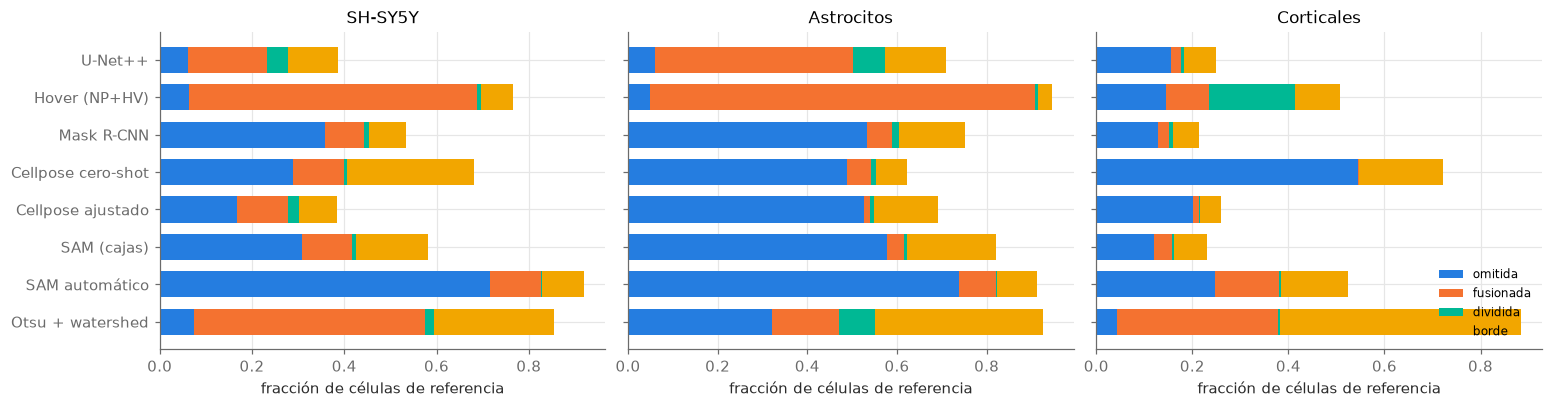

In [10]:
tx = R["taxonomy"].copy()
fr = tx.set_index(["model", "cell_type"])[["frac_omitida", "frac_fusionada", "frac_dividida", "frac_borde"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
names = {"frac_omitida": "omitida", "frac_fusionada": "fusionada", "frac_dividida": "dividida", "frac_borde": "borde"}
for ax, t in zip(axes, ["shsy5y", "astro", "cort"]):
    d = fr.xs(t, level="cell_type").reindex(models)
    left = np.zeros(len(d))
    for k, c in enumerate(d.columns):
        ax.barh([L[m] for m in d.index], d[c], left=left, color=CAT[k], label=names[c], height=0.7)
        left += d[c].to_numpy()
    ax.set(title=CELL_NAMES[t], xlabel="fracción de células de referencia")
axes[0].invert_yaxis(); axes[-1].legend(loc="lower right", fontsize=8)
plt.show()

In [11]:
fp = tx.groupby("model")[["err_falsa", "n_gt"]].sum()
fp = (fp.err_falsa / fp.n_gt).rename(index=L).sort_values()
display(Markdown("Predicciones falsas por célula de referencia (todas las imágenes): "
                 + "; ".join(f"{k}: {v:.2f}" for k, v in fp.items()) + "."))

Predicciones falsas por célula de referencia (todas las imágenes): Cellpose ajustado: 0.03; Mask R-CNN: 0.06; SAM (cajas): 0.06; Hover (NP+HV): 0.07; U-Net++: 0.14; Cellpose cero-shot: 0.27; SAM automático: 1.43; Otsu + watershed: 2.19.

## H1: preentrenamiento y fracción de datos

In [12]:
h1 = R["h1"]
rows = [dict(fracción=k, **{"Mask R-CNN − U-Net++ [IC 95 %]": ci(v["diff"], v["lo"], v["hi"]), "p (Wilcoxon)": v["p"],
                             "imágenes": v["n"], "semillas (Mask R-CNN, U-Net++)": v["seeds"]})
        for k, v in h1.items() if isinstance(v, dict)]
display(pd.DataFrame(rows))
if "parte1_refutada" in h1:
    display(Markdown(
        f"**H1, primera parte {'se refuta' if h1['parte1_refutada'] else 'no se refuta'}**: al 25 % del entrenamiento el IC de la "
        f"diferencia Mask R-CNN − U-Net++ "
        + ("queda entero por debajo de 0: la U-Net++ desde cero supera a Mask R-CNN preentrenado, el sentido contrario al de la "
           "hipótesis. "
           if h1.get("parte1_sentido_contrario") else
           ("incluye el 0. " if h1["parte1_refutada"] else "queda entero por encima de 0. "))
        + (f"**Segunda parte {'se refuta' if h1['parte2_refutada'] else 'no se refuta'}**: la diferencia al 100 % "
           f"{'no es menor' if h1['parte2_refutada'] else 'es menor'} que al 25 %." if "parte2_refutada" in h1 else "")))
    _s25 = h1["25 %"]["seeds"]
    if min(_s25) < 3:
        display(Markdown(
            f"El contraste al 25 % usa {_s25[0]} semilla{'s' if _s25[0] != 1 else ''} de Mask R-CNN y {_s25[1]} de U-Net++. La prueba "
            "pre-registrada es pareada por imagen, así que su IC recoge la variación entre imágenes de test pero no la variación entre "
            "entrenamientos: el veredicto vale para "
            + ("esa semilla" if max(_s25) == 1 else "esas semillas")
            + ". Como referencia de cuánto puede mover la diferencia otra semilla, la DE entre semillas del AP en los modelos completos es "
            + " y ".join(f"{S.ap_seed_sd[m]:.3f} en {L[m]}" for m in ("maskrcnn_main", "unetpp_main")
                         if m in S.index and np.isfinite(S.ap_seed_sd[m]))
            + " (tabla principal)."))
    # presupuesto de optimización de cada corrida: pasos de gradiente hasta el final y hasta la mejor época
    from project.config import RESULTS as _R
    from project.persist import load_pickle as _lp

    def _budget(run):
        d = _R / "seg" / run / "seed_00"
        if not (d / "history.pkl").exists():
            return None
        c = _lp(d / "config.pkl"); cfg = c.get("config", c)
        hist = pd.DataFrame(_lp(d / "history.pkl"))
        if "steps_per_epoch" in cfg:
            per = int(cfg["steps_per_epoch"]); unit = f"{per} pasos fijos de lotes de recortes por época"
        else:
            per = int(np.ceil(len(c["train_ids"]) / cfg.get("batch", 2))); unit = f"{len(c['train_ids'])} imágenes en lotes de {cfg.get('batch', 2)}"
        best = int(hist.val_loss.idxmin()) + 1
        return dict(epochs=len(hist), best=best, steps=len(hist) * per, steps_best=best * per, unit=unit)

    _b = {r: _budget(r) for r in ("maskrcnn_frac25", "unetpp_frac25", "maskrcnn_main", "unetpp_main")}
    if all(_b.values()):
        _rm = _b["maskrcnn_frac25"]["steps_best"] / _b["maskrcnn_main"]["steps_best"]
        _ru = _b["unetpp_frac25"]["steps_best"] / _b["unetpp_main"]["steps_best"]
        display(pd.DataFrame({r: {"épocas": v["epochs"], "mejor época": v["best"], "pasos de gradiente": v["steps"],
                                  "pasos hasta la mejor época": v["steps_best"], "unidad de época": v["unit"]}
                              for r, v in _b.items()}).T.rename(index={"maskrcnn_frac25": "Mask R-CNN (25 %)", "unetpp_frac25": "U-Net++ (25 %)",
                                                         "maskrcnn_main": "Mask R-CNN (100 %)", "unetpp_main": "U-Net++ (100 %)"}))
        display(Markdown(
            "**Condición de validez del contraste al 25 %.** Las dos familias no reducen igual su presupuesto de optimización al "
            f"reducir los datos. La época de Mask R-CNN recorre todas las imágenes de entrenamiento, así que al 25 % cada época "
            "tiene la cuarta parte de pasos y la parada temprana actúa antes: el modelo elegido vio "
            f"{100 * _rm:.0f} % de los pasos de gradiente que el de 100 %. La U-Net++ tiene 100 pasos fijos por época y al 25 % vio "
            f"{100 * _ru:.0f} % de los pasos del modelo completo, repitiendo más veces cada imagen. El contraste pre-registrado mide, "
            "por tanto, «preentrenamiento con la regla de parada de cada familia» y no solo el efecto del preentrenamiento: con el "
            "mismo número de pasos, la brecha al 25 % podría ser menor. El veredicto vale para el protocolo de entrenamiento "
            "descrito en el capítulo {doc}`12_seg_modelos`."))
else:
    display(Markdown("Las corridas al 25 % no terminaron dentro del presupuesto; H1 queda sin contrastar."))

,fracción,Mask R-CNN − U-Net++ [IC 95 %],p (Wilcoxon),imágenes,"semillas (Mask R-CNN, U-Net++)"
0,25 %,"-0.091 [-0.105, -0.078]",2.157e-16,93,"(1, 1)"
1,100 %,"0.014 [0.007, 0.021]",3.002e-03,93,"(3, 3)"


**H1, primera parte se refuta**: al 25 % del entrenamiento el IC de la diferencia Mask R-CNN − U-Net++ queda entero por debajo de 0: la U-Net++ desde cero supera a Mask R-CNN preentrenado, el sentido contrario al de la hipótesis. **Segunda parte se refuta**: la diferencia al 100 % no es menor que al 25 %.

El contraste al 25 % usa 1 semilla de Mask R-CNN y 1 de U-Net++. La prueba pre-registrada es pareada por imagen, así que su IC recoge la variación entre imágenes de test pero no la variación entre entrenamientos: el veredicto vale para esa semilla. Como referencia de cuánto puede mover la diferencia otra semilla, la DE entre semillas del AP en los modelos completos es 0.004 en Mask R-CNN y 0.002 en U-Net++ (tabla principal).

,épocas,mejor época,pasos de gradiente,pasos hasta la mejor época,unidad de época
Mask R-CNN (25 %),10,5,540,270,107 imágenes en lotes de 2
U-Net++ (25 %),35,34,3500,3400,100 pasos fijos de lotes de recortes por época
Mask R-CNN (100 %),24,20,5064,4220,421 imágenes en lotes de 2
U-Net++ (100 %),35,28,3500,2800,100 pasos fijos de lotes de recortes por época


**Condición de validez del contraste al 25 %.** Las dos familias no reducen igual su presupuesto de optimización al reducir los datos. La época de Mask R-CNN recorre todas las imágenes de entrenamiento, así que al 25 % cada época tiene la cuarta parte de pasos y la parada temprana actúa antes: el modelo elegido vio 6 % de los pasos de gradiente que el de 100 %. La U-Net++ tiene 100 pasos fijos por época y al 25 % vio 121 % de los pasos del modelo completo, repitiendo más veces cada imagen. El contraste pre-registrado mide, por tanto, «preentrenamiento con la regla de parada de cada familia» y no solo el efecto del preentrenamiento: con el mismo número de pasos, la brecha al 25 % podría ser menor. El veredicto vale para el protocolo de entrenamiento descrito en el capítulo {doc}`12_seg_modelos`.

## Casos cualitativos

La {numref}`fig-seg-casos` muestra, para el mejor modelo, una muestra aleatoria de imágenes de test elegida con semilla fija y los peores casos por AP. Los genera `python scripts/figs_results_seg.py`.

```{figure} images/gen/seg_casos.png
:name: fig-seg-casos
:width: 100%

*Predicciones del mejor modelo en test: muestra aleatoria (semilla 2026), cinco mejores y cinco peores imágenes por AP.* Verde: células emparejadas (IoU > 0.5); naranja: predicciones falsas o con IoU insuficiente; azul: células de referencia omitidas. Imágenes de Sartorius {cite:p}`sartorius2021`; figura elaborada por los autores.
```